In [5]:
!pip install yfinance

In [6]:
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt

In [7]:
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt

# Download the TCS historical prices

df = yf.download(
    "TCS.NS",
    period = "1y",
    interval = "1d",
    auto_adjust = True
)

# display the first five rows
print(df.head())

[*********************100%***********************]  1 of 1 completed

Price             Close         High          Low         Open   Volume
Ticker           TCS.NS       TCS.NS       TCS.NS       TCS.NS   TCS.NS
Date                                                                   
2025-10-23  2946.051514  2969.825503  2910.486604  2928.604555  5564758
2025-10-24  2936.465088  2962.156329  2931.767911  2952.570062  2684318
2025-10-27  2957.267578  2966.182854  2933.589544  2939.628939  1946312
2025-10-28  2931.384277  2962.347964  2914.416633  2948.735513  3470737
2025-10-29  2931.097168  2948.735806  2920.072961  2931.384569  2895420


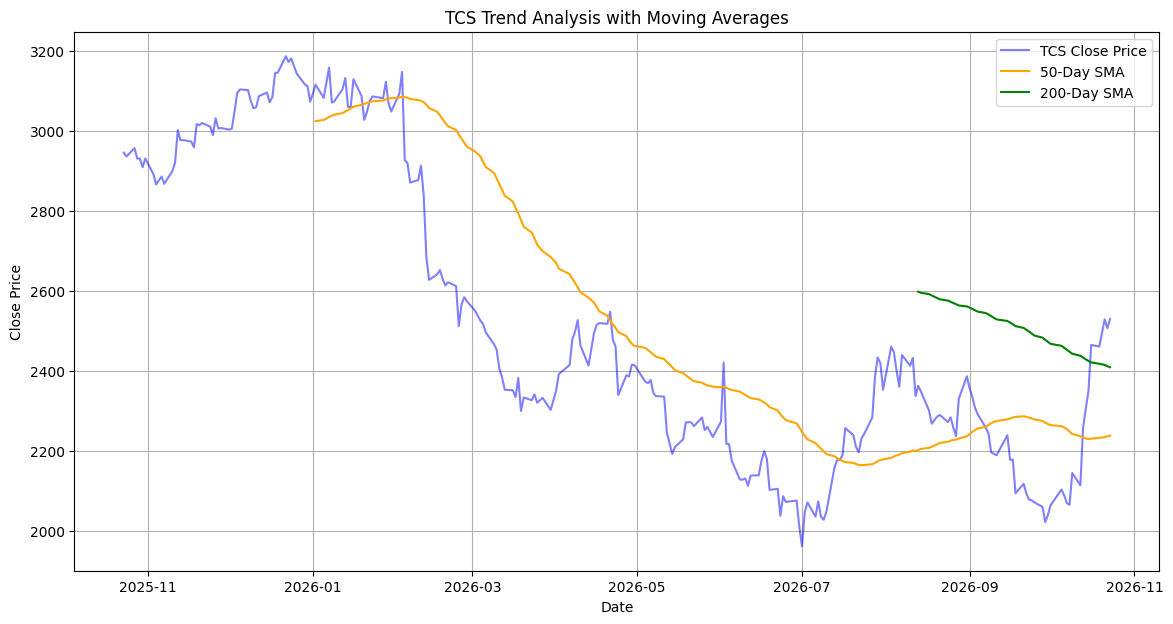

In [8]:
# Calculate the 50 day and 200 day simple moving averages
df['SMA_50']=df['Close'].rolling(window=50).mean()
df['SMA_200']=df['Close'].rolling(window=200).mean()

# Plot the closing price and the moving averages

plt.figure(figsize=(14,7))
plt.plot(df['Close'],label='TCS Close Price',color = 'blue',alpha=0.5)
plt.plot(df['SMA_50'],label='50-Day SMA',color = 'orange')
plt.plot(df['SMA_200'],label='200-Day SMA',color = 'green')
plt.title('TCS Trend Analysis with Moving Averages')
plt.xlabel('Date')
plt.ylabel('Close Price')
plt.legend()
plt.grid(True)
plt.show()


In [9]:
print("Total rows:", len(df))
print("Valid closing prices:", df["Close"].count())
print("Valid 50-day SMA:", df["SMA_50"].count())
print("Valid 200-day SMA:", df["SMA_200"].count())

Total rows: 248
Valid closing prices: Ticker
TCS.NS    248
dtype: int64
Valid 50-day SMA: 199
Valid 200-day SMA: 49


In [10]:
# Daily percentage returns
df["Daily_Returns"] = df["Close"].pct_change()*100

# Results

print(df[["Close","Daily_Returns"]].head(10))

Price             Close Daily_Returns
Ticker           TCS.NS              
Date                                 
2025-10-23  2946.051514           NaN
2025-10-24  2936.465088     -0.325399
2025-10-27  2957.267578      0.708419
2025-10-28  2931.384277     -0.875244
2025-10-29  2931.097168     -0.009794
2025-10-30  2909.719482     -0.729341
2025-10-31  2931.480225      0.747864
2025-11-03  2891.985107     -1.347276
2025-11-04  2866.485840     -0.881722
2025-11-06  2886.328857      0.692242


In [11]:
# Summary statistics of daily return

print("Average daily return:",
      df["Daily_Returns"].mean(),"%")

print("Best daily return:",
      df["Daily_Returns"].max(),"%")
print("Worst daily return:",
      df["Daily_Returns"].min(),"%")
print("Daily return volatility(standard deviation):",
      df["Daily_Returns"].std(),"%")

Average daily return: -0.04377264393053604 %
Best daily return: 6.7905840327078915 %
Worst daily return: -8.386124653812255 %
Daily return volatility(standard deviation): 1.8907075643693372 %


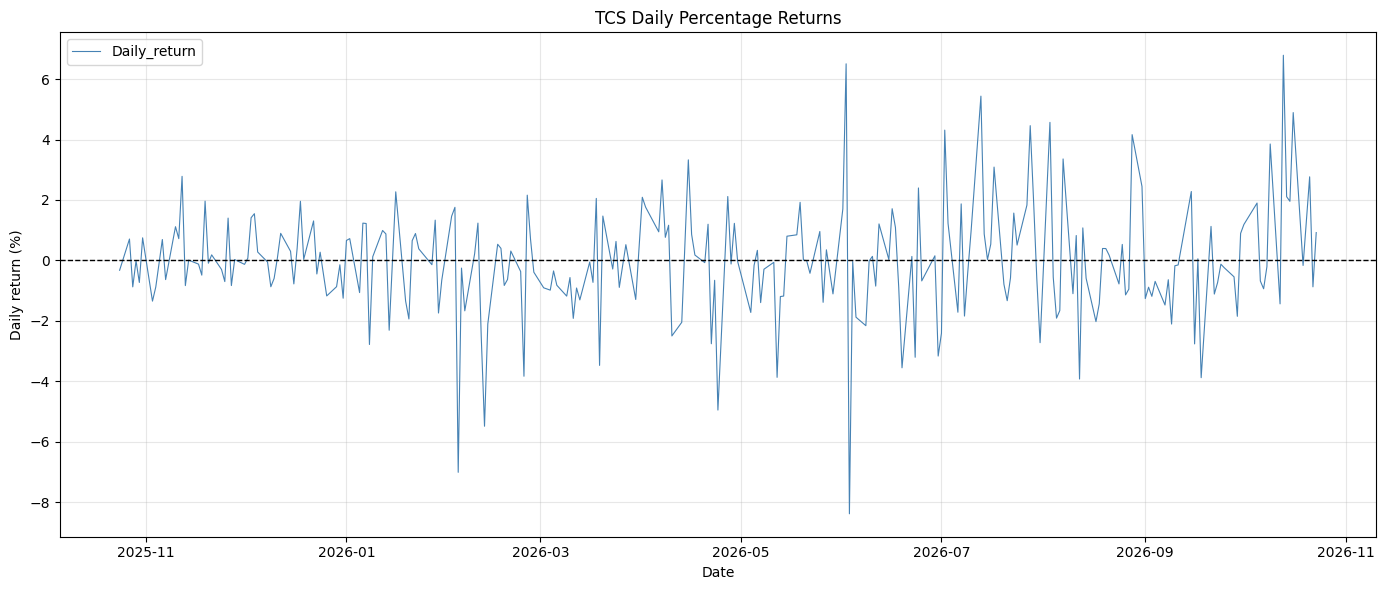

In [12]:
plt.figure(figsize=(14,6))
plt.plot(
    df.index,
    df["Daily_Returns"],
    color = "steelblue",
    linewidth = 0.8,
    label = "Daily_return"
)

plt.axhline(y=0 , color = "black" , linestyle = "--" , linewidth = 1)
plt.title("TCS Daily Percentage Returns")
plt.xlabel("Date")
plt.ylabel("Daily return (%)")
plt.legend()
plt.grid(True , alpha = 0.3)
plt.tight_layout()
plt.show()

In [13]:
# Monthly closing prices
monthly_close = df["Close"].resample("ME").last()

# Monthly percentage return
monthly_returns = monthly_close.pct_change()*100

# Monthly returns
print(monthly_returns)

Ticker         TCS.NS
Date                 
2025-10-31        NaN
2025-11-30   2.599743
2025-12-31   2.189642
2026-01-31  -0.795671
2026-02-28 -15.573484
2026-03-31 -10.559648
2026-04-30   4.875162
2026-05-31  -7.452670
2026-06-30 -10.066839
2026-07-31  17.084440
2026-08-31   1.424593
2026-09-30 -14.533409
2026-10-31  24.034407


<Figure size 1200x600 with 0 Axes>

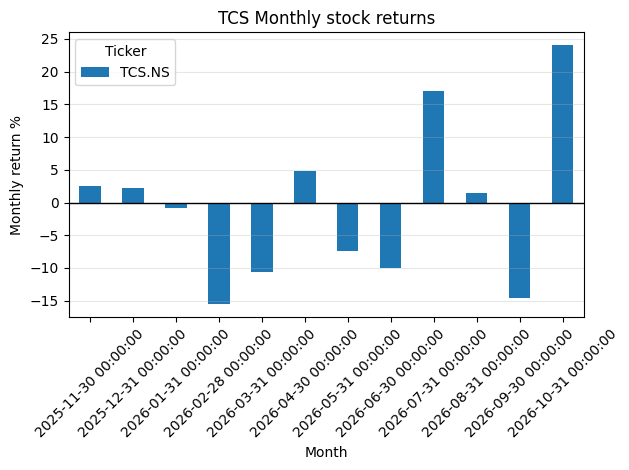

In [14]:
plt.figure(figsize=(12,6))
monthly_returns.dropna().plot(kind="bar")

plt.title("TCS Monthly stock returns")
plt.xlabel("Month")
plt.ylabel("Monthly return %")
plt.axhline(y=0 , color = "black", linewidth = 1)
plt.xticks(rotation = 45)
plt.grid(axis = "y" , alpha = 0.3)
plt.tight_layout()
plt.show()

In [15]:
from sklearn.linear_model import LinearRegression
import numpy as np

df["Day_Number"] = np.arange(len(df))

X = df[["Day_Number"]]
Y = df["Close"]
model = LinearRegression()
model.fit(X,Y)

df["Regression_Trend"] = model.predict(X)

print("Slope:" , model.coef_[0])
print("Intercept:" , model.intercept_)
print("R_Squared:" , model.score(X,Y))

Slope: [-4.32481705]
Intercept: [3061.84489579]
R_Squared: 0.7070152955642472


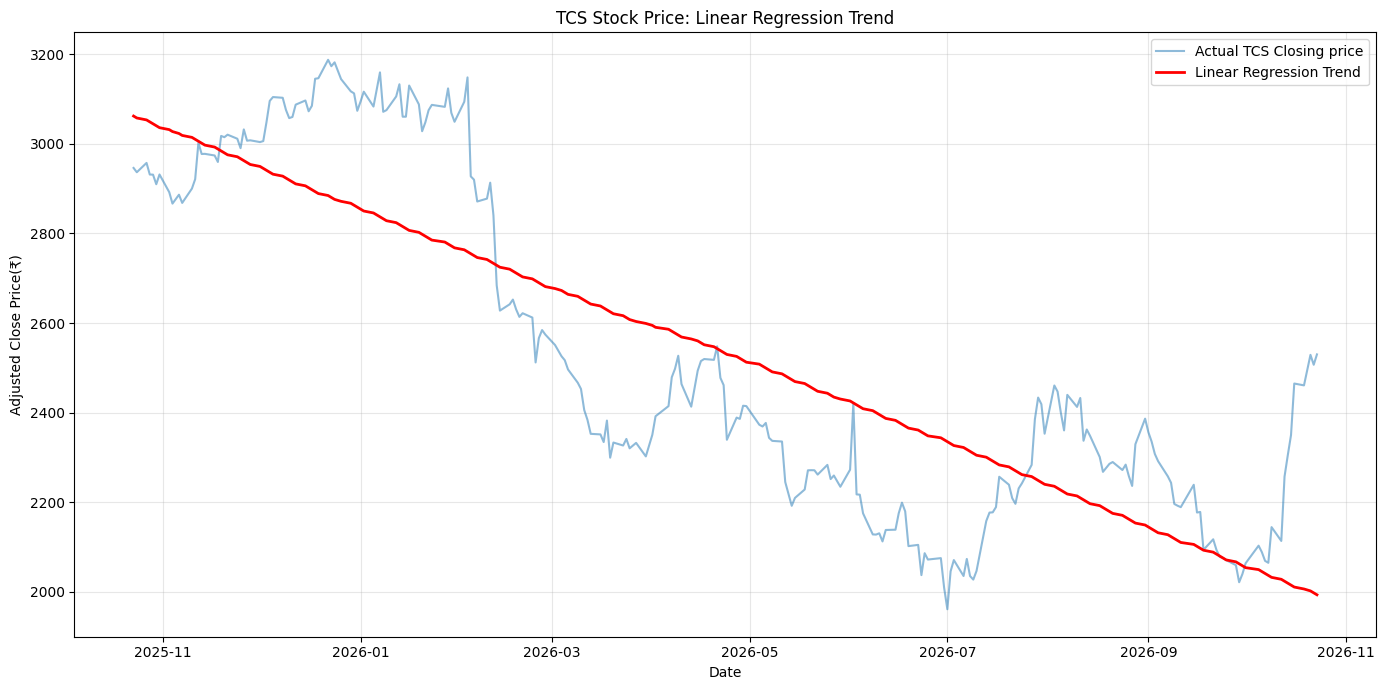

In [17]:
plt.figure(figsize=(14,7))
plt.plot(
    df.index , df["Close"],
    label = "Actual TCS Closing price",
    alpha = 0.5
)

plt.plot(
    df.index , df["Regression_Trend"],
    label = "Linear Regression Trend",
    color = "red",
    linewidth = 2
)

plt.title("TCS Stock Price: Linear Regression Trend")
plt.xlabel("Date")
plt.ylabel("Adjusted Close Price(₹)")
plt.legend()
plt.grid(True , alpha = 0.3)
plt.tight_layout()
plt.show()


In [19]:
from sklearn.metrics import mean_absolute_error , mean_squared_error
import numpy as np

# Comparision of actual prices with regression estimates

y_actual = df["Close"]
y_predicted = df["Regression_Trend"]

mae = mean_absolute_error(y_actual,y_predicted)
rmse = np.sqrt(mean_squared_error(y_actual,y_predicted))

print("Mean Absolute Error (MAE):" , round(mae,2))
print("Root Mean Squared Error (RMSE):" , round(rmse,2))


Mean Absolute Error (MAE): 170.13
Root Mean Squared Error (RMSE): 199.31


In [25]:
# overall price change
first_price = df["Close"].iloc[0].iloc[0]
last_price = df["Close"].iloc[-1].iloc[0]

price_change = last_price - first_price
percentage_change = (price_change / first_price) * 100

print(f"Starting price: ₹{first_price:.2f}")
print(f"Ending price: ₹{last_price:.2f}")
print(f"Absolute change: ₹{price_change:.2f}")
print(f"Percentage change: {percentage_change:.2f}%")

Starting price: ₹2946.05
Ending price: ₹2530.00
Absolute change: ₹-416.05
Percentage change: -14.12%


## Conclusion

This project analyzed approximately one year of historical TCS stock price data using Python. The adjusted closing price declined by approximately 14.12% over the period studied. Moving averages helped examine longer-term price trends, while daily and monthly returns highlighted changes in performance over time.

A simple linear regression model was used to describe the historical price trend. Its R-squared value was approximately 0.707, with an in-sample MAE of ₹170.13 and RMSE of ₹199.31. These metrics describe how well the model fitted the historical data and do not establish its ability to predict future prices.

Overall, the project provided practical experience in data collection, cleaning and analysis, visualization, feature calculation, and basic machine learning evaluation using Python.

*Note: This analysis is for educational purposes only and is not investment advice.*